# IT135IU – Deliverable 3: Analysis Notebook
## Where should Seoul assess additional air-quality monitoring first? (Seoul air quality, 2022)

| Member | StudentID | Role |
|---|---|---|
| Lưu Ngọc Quỳnh Anh | ITDSIU25003 | Product owner (EPO) |
| Nguyễn Vinh | ITDSIU25052 | Data engineer (DE) |
| Nguyễn Thị Kim Ngân | ITDSIU25023 | Data analyst (DA) |
| Dương Ngọc Bảo Thy | ITDSIU25046 | Visualisation lead |
| Nguyễn Hoàng Thiên Tứ | ITDSIU25050 | Reproducibility lead |
| Trần Lê Ngọc Thủy | ITDSIU25045 | Ethics and privacy officer |

### 1. Decision question, user and success criteria
**Decision question.** Which 3–5 of Seoul's 25 districts should be prioritised for further assessment of air-quality monitoring coverage, based on 2022 pollution hazard and population exposure?

**Who acts on the answer.** Seoul's Air Quality Integrated Analysis Center (the unit named in the recommendation at the end of this notebook).

**Success criteria.** The answer is useful if: (1) it names 3–5 districts; (2) every named district is in the top quartile (≥ 75th percentile) of at least one pollution-hazard measure *and* at least one exposure measure; (3) the shortlist is checked for sensitivity to the quartile cut-off (0.70 / 0.75 / 0.80); (4) its assumptions and limitations are stated.

**Scope note.** The data contain exactly one monitoring station per district (station codes 101–125). The data therefore cannot show *where inside a district* coverage is missing; the recommendation is about which districts to assess first, not where to install a device.

### 2. Data source and responsible use
| Item | Entry |
|---|---|
| File used | `seoul_air_quality_2022_english.csv` (hourly readings, 25 districts, 2022, joined with district population, area and households) |
| Source URL | https://data.seoul.go.kr/dataList/OA-15526/A/1/datasetView.do  |
| Publisher | Seoul Metropolitan Government Research Institute of Public Health and Environment (서울특별시 보건환경연구원), via Seoul Open Data Plaza |
| Date retrieved | 21/09/2026 |
| Terms of use | KOGL Type 1 (Gonggongnuri Type 1): commercial use and modification permitted attribution required. |
| Size | 216,545 rows × 17 columns (the full grid would be 25 × 8,760 = 219,000 hourly rows; 2,455 are absent) |
| Personal data | None. Readings are per monitoring station; population fields are district-level totals. |
| Third-party code | Open-source Python libraries listed in `requirements.txt` (pandas, numpy, matplotlib, seaborn, scipy, adjustText). |
| AI tools | ChatGPT helped us to fix the bug of the code and finalize our first idea. |
| Known limitations | One year (2022); one station per district; imputed values (see cleaning log); Dongdaemun-gu has a 551-hour gap in August 2022. |


## Import library

Dependencies are listed in `requirements.txt` (install with `pip install -r requirements.txt`). The analysis contains no random steps; a fixed seed is set anyway so that any future sampling is reproducible.

In [1]:
import random
import sys
import numpy as np
import pandas as pd
import matplotlib, seaborn, scipy, adjustText

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('Python', sys.version.split()[0])
for m in (pd, np, matplotlib, seaborn, scipy, adjustText):
    print(m.__name__, getattr(m, '__version__', 'n/a'))
print('SEED =', SEED)

Python 3.14.5
pandas 3.0.6
numpy 2.5.4
matplotlib 3.11.2
seaborn 0.13.2
scipy 1.18.1
adjustText 1.4.0
SEED = 42


In [2]:
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy import stats
from adjustText import adjust_text
df=pd.read_csv('seoul_air_quality_2022_english.csv')
df_raw=df.copy()
df.head(10)

,datetime,station_code,district,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
0,1/1/2022 0:00,101,Jongno-gu,0.4,0.016,0.026,23.0,12.0,0.003,152211,23.91,6365,72524,72980,79231,1111000000,2022
1,1/1/2022 0:00,102,Jung-gu,0.4,0.024,0.016,25.0,10.0,0.003,130785,9.96,13131,63139,63377,67408,1114000000,2022
2,1/1/2022 0:00,103,Yongsan-gu,0.4,0.020,0.020,24.0,13.0,0.003,233284,21.87,10668,109805,113012,120272,1117000000,2022
3,1/1/2022 0:00,104,Eunpyeong-gu,0.8,0.019,0.019,19.0,10.0,0.004,470602,29.71,15838,213876,224163,246439,1138000000,2022
4,1/1/2022 0:00,105,Seodaemun-gu,0.7,0.020,0.019,23.0,13.0,NaN,319554,17.63,18129,145797,150094,169460,1141000000,2022
5,1/1/2022 0:00,106,Mapo-gu,0.4,0.026,0.014,18.0,6.0,0.002,375585,23.85,15745,180084,175006,200579,1144000000,2022
6,1/1/2022 0:00,107,Seongdong-gu,0.3,0.017,0.024,19.0,5.0,0.003,288234,16.82,17136,133305,139691,148543,1120000000,2022
7,1/1/2022 0:00,108,Gwangjin-gu,0.7,0.025,0.018,17.0,8.0,0.001,351252,17.06,20586,169291,168197,183055,1121500000,2022
8,1/1/2022 0:00,109,Dongdaemun-gu,0.4,0.021,0.022,16.0,11.0,0.002,353601,14.22,24873,169873,171903,181698,1123000000,2022
9,1/1/2022 0:00,110,Jungnang-gu,0.4,0.019,0.025,21.0,8.0,0.003,390140,18.50,21092,187413,191422,198718,1126000000,2022


## Exploratory Data Analysis

In [3]:
print(df.shape)
df.info()
display(df.describe())
df.isnull().sum()
print((df.isnull().sum())*100/len(df))
#Check duplicated date
display(df.duplicated(subset=['district','datetime']).sum())


(216545, 17)
<class 'pandas.DataFrame'>
RangeIndex: 216545 entries, 0 to 216544
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   datetime            216545 non-null  str    
 1   station_code        216545 non-null  int64  
 2   district            216545 non-null  str    
 3   CO                  215142 non-null  float64
 4   NO2                 215540 non-null  float64
 5   O3                  215209 non-null  float64
 6   PM10                214136 non-null  float64
 7   PM2.5               214805 non-null  float64
 8   SO2                 214839 non-null  float64
 9   population          216545 non-null  int64  
 10  area_km2            216545 non-null  float64
 11  population_density  216545 non-null  int64  
 12  households          216545 non-null  int64  
 13  male_population     216545 non-null  int64  
 14  female_population   216545 non-null  int64  
 15  district_code       216545 non-n

,station_code,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
count,216545.000000,215142.000000,215540.000000,215209.000000,214136.000000,214805.000000,214839.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,2.165450e+05,216545.0
mean,113.006812,0.437070,0.020868,0.029275,32.861625,18.378618,0.002886,386814.131368,24.237395,16790.225316,177867.498377,187068.209924,199745.921444,1.141691e+09,2022.0
std,7.214851,0.185666,0.013388,0.019398,22.842114,13.907109,0.000843,122930.793712,9.121672,4603.200653,55573.744517,59252.031769,63846.926920,1.863222e+07,0.0
min,101.000000,0.100000,0.001000,0.000000,1.000000,1.000000,0.001000,130785.000000,9.960000,6365.000000,63139.000000,63377.000000,67408.000000,1.111000e+09,2022.0
25%,107.000000,0.300000,0.011000,0.015000,19.000000,9.000000,0.002000,313989.000000,17.410000,13862.000000,144313.000000,150094.000000,161814.000000,1.126000e+09,2022.0
50%,113.000000,0.400000,0.017000,0.027000,28.000000,15.000000,0.003000,390432.000000,23.600000,16951.000000,181187.000000,191422.000000,201821.000000,1.141000e+09,2022.0
75%,119.000000,0.500000,0.028000,0.040000,41.000000,24.000000,0.003000,464037.000000,29.570000,19616.000000,202169.000000,224163.000000,237062.000000,1.156000e+09,2022.0
max,125.000000,2.000000,0.096000,0.167000,482.000000,126.000000,0.016000,664514.000000,46.970000,25509.000000,284853.000000,319743.000000,344771.000000,1.174000e+09,2022.0


datetime              0.000000
station_code          0.000000
district              0.000000
CO                    0.647902
NO2                   0.464107
O3                    0.616962
PM10                  1.112471
PM2.5                 0.803528
SO2                   0.787827
population            0.000000
area_km2              0.000000
population_density    0.000000
households            0.000000
male_population       0.000000
female_population     0.000000
district_code         0.000000
year                  0.000000
dtype: float64


np.int64(0)

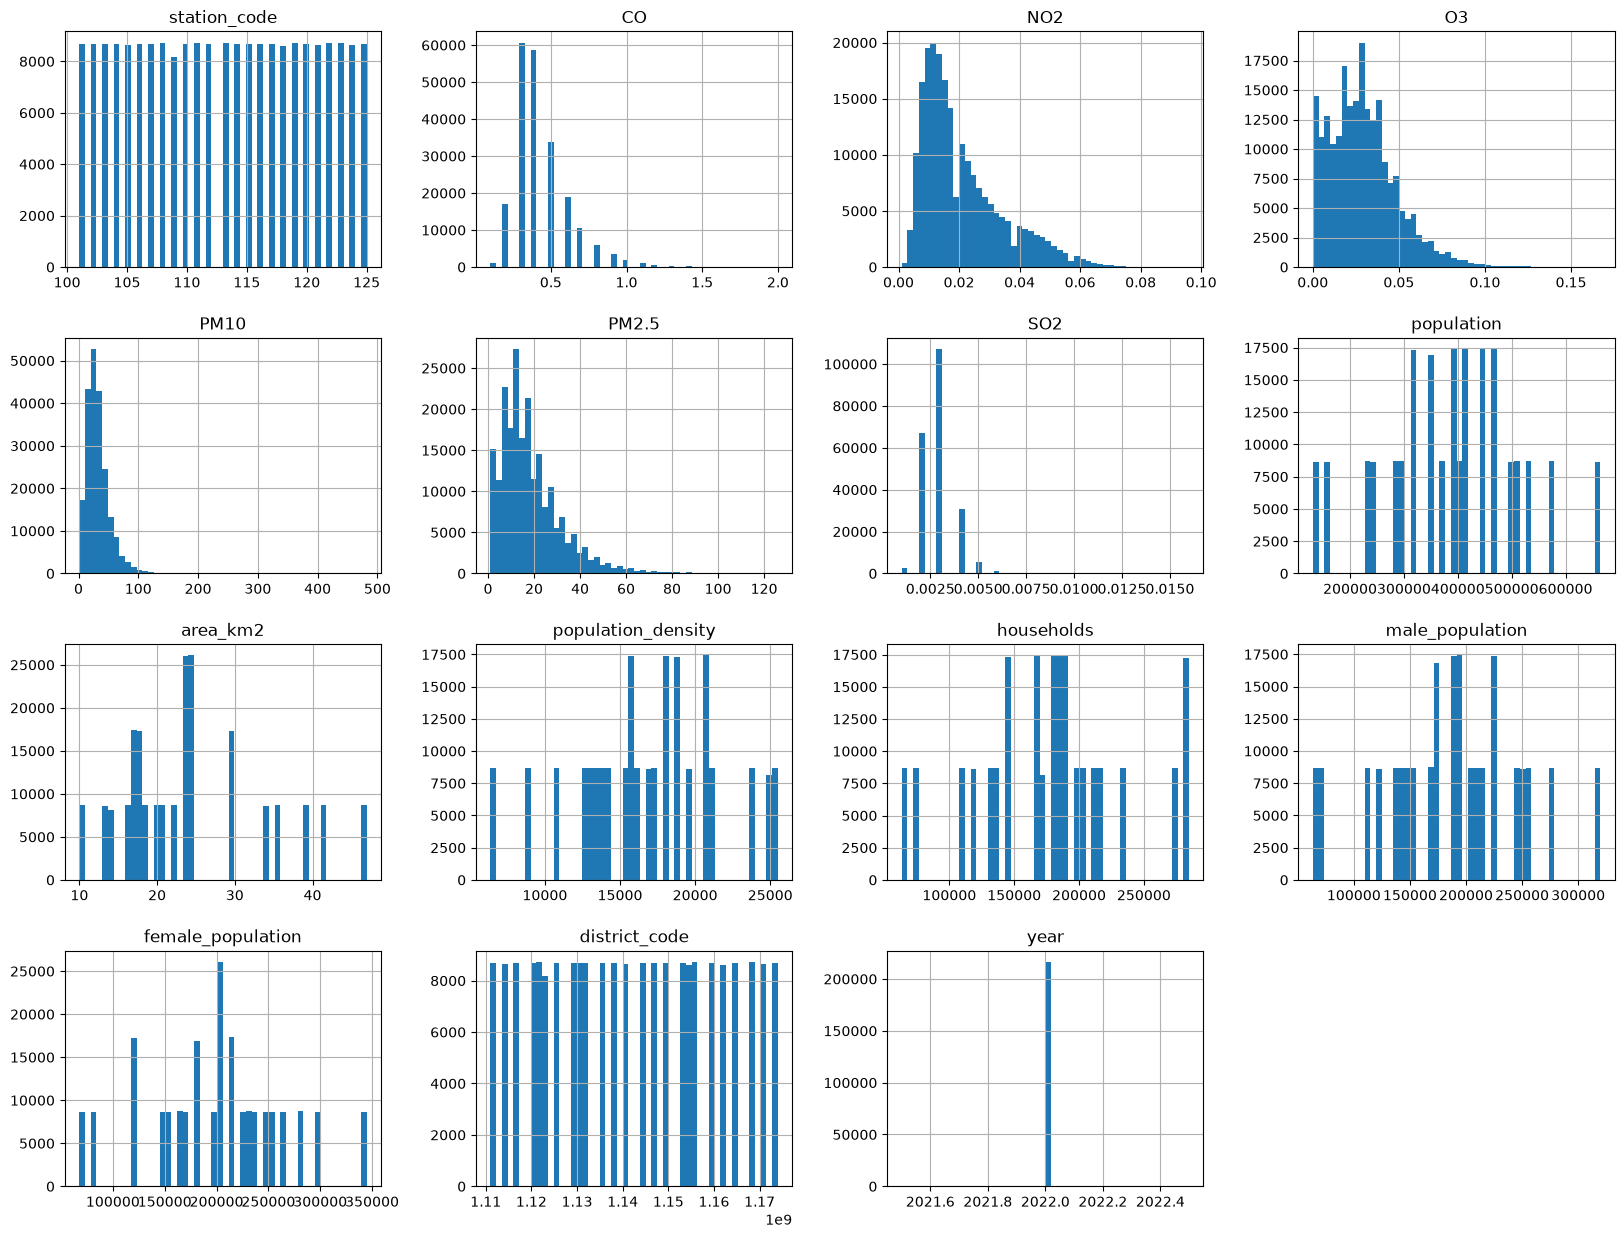

In [4]:
df.hist(bins=50,figsize=(20,15))
plt.show()

## Data Profile Table

In [5]:
df_prof = df_raw.copy()
df_prof['datetime']=pd.to_datetime(df_prof['datetime'])
profile=pd.DataFrame({'Data Type': df_raw.dtypes.astype(str),
                     'Missing Count': df_raw.isnull().sum(),
                     'Missing Percent':df_raw.isnull().sum()*100/len(df_raw),
                     'Unique Values':df_raw.nunique(),
                     'Minimum':df_prof.min(numeric_only=False),
                     'Maximum':df_prof.max(numeric_only=False)})
display(profile)
                     

,Data Type,Missing Count,Missing Percent,Unique Values,Minimum,Maximum
datetime,str,0,0.000000,8760,2022-01-01 00:00:00,2022-12-31 23:00:00
station_code,int64,0,0.000000,25,101,125
district,str,0,0.000000,25,Dobong-gu,Yongsan-gu
CO,float64,1403,0.647902,20,0.1,2.0
NO2,float64,1005,0.464107,93,0.001,0.096
O3,float64,1336,0.616962,154,0.0,0.167
PM10,float64,2409,1.112471,359,1.0,482.0
PM2.5,float64,1740,0.803528,124,1.0,126.0
SO2,float64,1706,0.787827,15,0.001,0.016
population,int64,0,0.000000,25,130785,664514


## Data Cleaning and Preprocessing

**Data cleaning.** Pollutant columns CO, NO2, O3, PM10, PM2.5 and SO2 contain missing values in about 0.648%, 0.464%, 0.617%, 1.11%, 0.803% and 0.788% of rows respectively (9,599 missing values in total). The rate is low, but the gaps are scattered across all pollutant columns. The data form a continuous hourly time series, so deleting rows would break temporal continuity and distort comparisons between districts.

Seoul's air quality follows hourly and seasonal cycles, and `df.describe()` and the histograms show that the mean is higher than the median, i.e. right-skewed distributions. The median is therefore less sensitive to extreme readings than the mean, so missing values were filled with the **median of the same station, hour of day and season**.

In [6]:
df['datetime']=pd.to_datetime(df_prof['datetime'])
df['hour']=df['datetime'].dt.hour
df['month']=df['datetime'].dt.month
df['date']=df['datetime'].dt.date
pollutants=['CO','NO2','O3','PM10','PM2.5','SO2']
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Spring"
    elif month in [6,7,8]:
        return "Summer"
    else:
        return "Autumn"
df['season']=df['month'].apply(get_season)
for pollutant in pollutants:
    df[pollutant]=df[pollutant].fillna(df.groupby(['station_code','hour','season'])[pollutant].transform('median'))


After imputation, a unit difference was identified: particulate matter (PM10, PM2.5) is recorded in µg/m³, while the gaseous pollutants (NO2, SO2, O3, CO) are recorded in ppm. To compare them with concentration thresholds, the gases were converted to µg/m³ at 25 °C and 1 atm. The converted values are stored in new columns (`NO2_ugm3`, `SO2_ugm3`, `O3_ugm3`, `CO_ugm3`) so the original readings are preserved.

### Data Quality and Missing-Value Treatment

The dataset contains missing pollutant measurements. To reduce the impact of missing values on subsequent analyses, the group applied group-based median imputation using station code, hour and season.

Imputed values are estimates rather than original monitoring observations. Therefore, descriptive statistics and visualizations based on the imputed dataset may differ from those calculated using observed measurements only.

This treatment may reduce the visibility of extreme pollution events and should be considered when interpreting the findings.

The group acknowledges that imputation does not recover the true missing measurements and that the resulting analysis remains subject to uncertainty.

In [7]:
#unit normalization
df['NO2_ugm3']=df['NO2']*1880
df['SO2_ugm3']=df['SO2']*2620
df['O3_ugm3']=df['O3']*1960
df['CO_ugm3']=df['CO']*1145
display(df[['NO2','NO2_ugm3','SO2','SO2_ugm3','O3','O3_ugm3','CO','CO_ugm3']].head())

,NO2,NO2_ugm3,SO2,SO2_ugm3,O3,O3_ugm3,CO,CO_ugm3
0,0.016,30.08,0.003,7.86,0.026,50.96,0.4,458.0
1,0.024,45.12,0.003,7.86,0.016,31.36,0.4,458.0
2,0.020,37.60,0.003,7.86,0.020,39.20,0.4,458.0
3,0.019,35.72,0.004,10.48,0.019,37.24,0.8,916.0
4,0.020,37.60,0.003,7.86,0.019,37.24,0.7,801.5


## Check missing values after preparing proccess

In [8]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 216545 entries, 0 to 216544
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   datetime            216545 non-null  datetime64[us]
 1   station_code        216545 non-null  int64         
 2   district            216545 non-null  str           
 3   CO                  216545 non-null  float64       
 4   NO2                 216545 non-null  float64       
 5   O3                  216545 non-null  float64       
 6   PM10                216545 non-null  float64       
 7   PM2.5               216545 non-null  float64       
 8   SO2                 216545 non-null  float64       
 9   population          216545 non-null  int64         
 10  area_km2            216545 non-null  float64       
 11  population_density  216545 non-null  int64         
 12  households          216545 non-null  int64         
 13  male_population     216545 non-null  int

None

In [9]:
hour_count=df.groupby('district').size().reset_index(name='total_hours')
print(hour_count)

           district  total_hours
0         Dobong-gu         8700
1     Dongdaemun-gu         8169
2        Dongjak-gu         8684
3      Eunpyeong-gu         8689
4        Gangbuk-gu         8688
5       Gangdong-gu         8685
6        Gangnam-gu         8708
7        Gangseo-gu         8679
8      Geumcheon-gu         8603
9           Guro-gu         8692
10        Gwanak-gu         8624
11      Gwangjin-gu         8732
12        Jongno-gu         8673
13          Jung-gu         8661
14      Jungnang-gu         8694
15          Mapo-gu         8692
16         Nowon-gu         8695
17        Seocho-gu         8702
18     Seodaemun-gu         8650
19      Seongbuk-gu         8703
20     Seongdong-gu         8695
21        Songpa-gu         8646
22     Yangcheon-gu         8683
23  Yeongdeungpo-gu         8709
24       Yongsan-gu         8689


## Cleaning log

In [10]:
cleaning_log=[]
def log_action(Step,Issue,Action,Reason):
    cleaning_log.append({'Step':Step,'Issue':Issue,'Action':Action,'Reason':Reason})
initial_rows=len(df)
n_missing=df_raw[pollutants].isnull().sum()
n_dup=int(df.duplicated(subset=['district','datetime']).sum())
steps=[
 ('Datetime stored as string','Convert datetime to datetime format','Enable time-based analysis and aggregation'),
 ('Missing temporal features','Extract hour, month, date, season','Support grouped imputation and daily aggregation'),
 ('Possible duplicate records',f'Checked duplicates on (district, datetime): {n_dup} found','Ensure consistency without unnecessary row removal'),
 (f'Missing pollutant values: {int(n_missing.sum()):,} cells (CO {n_missing["CO"]}, NO2 {n_missing["NO2"]}, O3 {n_missing["O3"]}, PM10 {n_missing["PM10"]}, PM2.5 {n_missing["PM2.5"]}, SO2 {n_missing["SO2"]})','Impute with the median grouped by station, hour and season','Keep observations while respecting station-specific and daily/seasonal patterns. Imputed values are estimates, not measurements.'),
 (f'Missing hourly records: {25*8760-len(df_raw):,} rows (largest gap: Dongdaemun-gu, 551 consecutive hours, 8-31 Aug 2022)','Report missing timestamps; no rows were invented','Avoid inventing observations that could distort pollution patterns and daily exceedances. Dongdaemun-gu annual averages may be biased upward because a low-pollution summer period is missing.'),
 ('Different measurement units across pollutants','Convert NO2 x1880, SO2 x2620, O3 x1960, CO x1145 (ppm to ug/m3, assumes 25 C and 1 atm); originals kept','Allow comparison with concentration thresholds; conversion assumption documented'),
 (f'Potential outliers (PM10 maximum = {df_raw["PM10"].max():.0f} ug/m3; O3 minimum = {df_raw["O3"].min()}; PM minimum = {df_raw["PM2.5"].min():.0f})','Retain all of them','No evidence of measurement error; extreme values may be genuine pollution events or low readings'),
 ('Incomplete days','Keep only district-days with at least 18 hourly readings for each of PM2.5, PM10 and NO2 (daily_valid). The count is taken after imputation, so the rule screens missing timestamps rather than missing readings. Dongdaemun-gu keeps 342 of 365 days.','Daily means based on very few hours are unreliable'),
 ('Hourly measurements vs daily guidelines','Aggregate hourly values to daily mean and median by district','Compare with 24-hour guideline values and compare districts'),
 ('Need a consistent criterion for exceedances','Use WHO 2021 24-hour guideline values on daily means: PM2.5 > 15, PM10 > 45, NO2 > 25 ug/m3','Consistent, citable reference for identifying and comparing exceedance days'),
 ('NO2 exceeds 25 ug/m3 on almost every day','Report exceedance days per pollutant alongside the combined count. This presentation was chosen after seeing that the combined count is nearly saturated (post-hoc decision).','The combined count hides differences between districts'),
]
for n,(a,b,c) in enumerate(steps,1):
    log_action(n,a,b,c)
log_df=pd.DataFrame(cleaning_log)
pd.set_option('display.max_colwidth',None)
display(log_df)

,Step,Issue,Action,Reason
0,1,Datetime stored as string,Convert datetime to datetime format,Enable time-based analysis and aggregation
1,2,Missing temporal features,"Extract hour, month, date, season",Support grouped imputation and daily aggregation
2,3,Possible duplicate records,"Checked duplicates on (district, datetime): 0 found",Ensure consistency without unnecessary row removal
3,4,"Missing pollutant values: 9,599 cells (CO 1403, NO2 1005, O3 1336, PM10 2409, PM2.5 1740, SO2 1706)","Impute with the median grouped by station, hour and season","Keep observations while respecting station-specific and daily/seasonal patterns. Imputed values are estimates, not measurements."
4,5,"Missing hourly records: 2,455 rows (largest gap: Dongdaemun-gu, 551 consecutive hours, 8-31 Aug 2022)",Report missing timestamps; no rows were invented,Avoid inventing observations that could distort pollution patterns and daily exceedances. Dongdaemun-gu annual averages may be biased upward because a low-pollution summer period is missing.
5,6,Different measurement units across pollutants,"Convert NO2 x1880, SO2 x2620, O3 x1960, CO x1145 (ppm to ug/m3, assumes 25 C and 1 atm); originals kept",Allow comparison with concentration thresholds; conversion assumption documented
6,7,Potential outliers (PM10 maximum = 482 ug/m3; O3 minimum = 0.0; PM minimum = 1),Retain all of them,No evidence of measurement error; extreme values may be genuine pollution events or low readings
7,8,Incomplete days,"Keep only district-days with at least 18 hourly readings for each of PM2.5, PM10 and NO2 (daily_valid). The count is taken after imputation, so the rule screens missing timestamps rather than missing readings. Dongdaemun-gu keeps 342 of 365 days.",Daily means based on very few hours are unreliable
8,9,Hourly measurements vs daily guidelines,Aggregate hourly values to daily mean and median by district,Compare with 24-hour guideline values and compare districts
9,10,Need a consistent criterion for exceedances,"Use WHO 2021 24-hour guideline values on daily means: PM2.5 > 15, PM10 > 45, NO2 > 25 ug/m3","Consistent, citable reference for identifying and comparing exceedance days"


2455


,district,gap_id,start,end,hours
34,Dongdaemun-gu,35,2022-08-08 18:00:00,2022-08-31 16:00:00,551
279,Gwanak-gu,280,2022-11-11 17:00:00,2022-11-14 17:00:00,73
214,Geumcheon-gu,215,2022-04-02 05:00:00,2022-04-04 11:00:00,55
526,Songpa-gu,527,2022-07-22 17:00:00,2022-07-24 12:00:00,44
223,Geumcheon-gu,224,2022-08-02 11:00:00,2022-08-03 16:00:00,30
126,Gangdong-gu,127,2022-07-14 15:00:00,2022-07-15 20:00:00,30
431,Seodaemun-gu,432,2022-03-07 09:00:00,2022-03-08 14:00:00,30
412,Seocho-gu,413,2022-04-25 14:00:00,2022-04-26 16:00:00,27
469,Seongbuk-gu,470,2022-09-27 13:00:00,2022-09-28 15:00:00,27
6,Dobong-gu,7,2022-04-27 12:00:00,2022-04-28 14:00:00,27


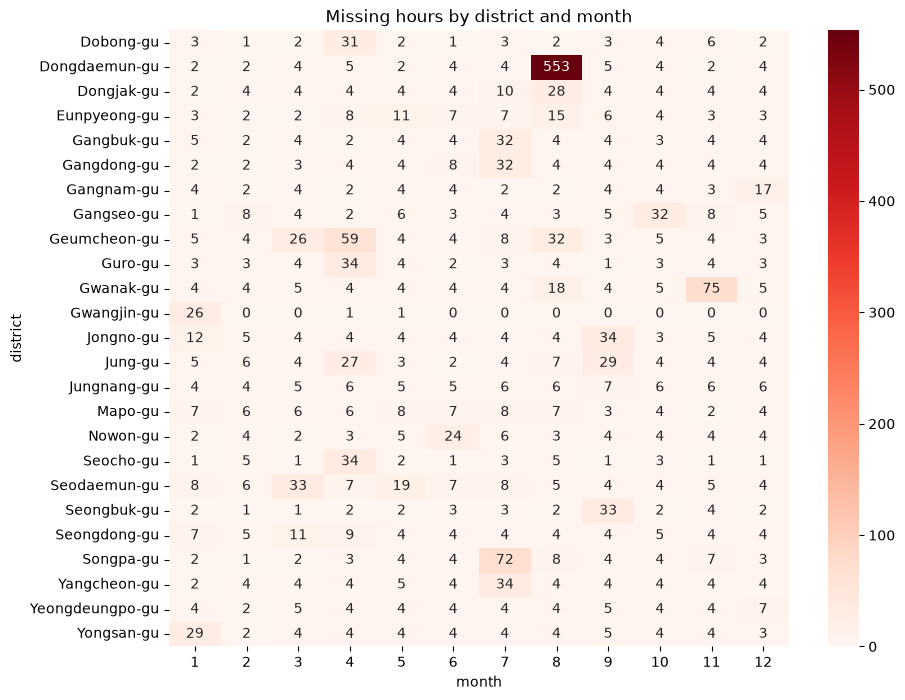

In [11]:

full_idx = pd.date_range('2022-01-01 00:00', '2022-12-31 23:00', freq='h')
full = pd.MultiIndex.from_product(
    [df['district'].unique(), full_idx], names=['district', 'datetime']
).to_frame(index=False)


merged = full.merge(df[['district', 'datetime']].assign(present=1),
                    on=['district', 'datetime'], how='left')
missing_rows = merged[merged['present'].isna()].sort_values(['district', 'datetime'])
print(len(missing_rows))   

gap_id = (missing_rows.groupby('district')['datetime'].diff() != pd.Timedelta(hours=1)).cumsum()
gaps = (missing_rows.assign(gap_id=gap_id)
        .groupby(['district', 'gap_id'])
        .agg(start=('datetime', 'min'), end=('datetime', 'max'), hours=('datetime', 'size'))
        .reset_index())
display(gaps.sort_values('hours', ascending=False).head(10))


missing_rows['month'] = missing_rows['datetime'].dt.month
pivot = missing_rows.pivot_table(index='district', columns='month',
                                 values='datetime', aggfunc='size', fill_value=0)
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, annot=True, fmt='d', cmap='Reds')
plt.title('Missing hours by district and month')
plt.show()

**Note on missing hours.** 2,455 hourly rows (1.1%) are absent. Dongdaemun-gu is missing 551 consecutive hours (8 Aug 18:00 – 31 Aug 16:00) and therefore has only 342 valid days. Because the gap falls in a low-pollution period, its annual averages are likely biased upward and should be read with caution.

## Exploratory Data Analysis (daily and district level)

In [12]:

daily_df=df.groupby(['district','date']).agg(
    n_hours = ('datetime','size'),
    PM25_median=('PM2.5','median'),
    PM10_median=('PM10','median'),
    NO2_median=('NO2_ugm3','median'),
    PM25_mean=('PM2.5', 'mean'),
    PM10_mean=('PM10', 'mean'),
    NO2_mean=('NO2_ugm3', 'mean'),
    population=('population','first'),
    po_density=('population_density','first'),
    area=('area_km2','first')
).reset_index()

district_median = daily_df.groupby('district').agg(
    PM25_typical=('PM25_median', 'median'),
    PM10_typical=('PM10_median', 'median'),
    NO2_typical=('NO2_median', 'median')
).reset_index()


display(district_median)
MIN_HOURS = 1
daily_df = df.groupby(['district', 'date']).agg(
    n_hours=('datetime', 'nunique'),

    PM25_hours=('PM2.5', 'count'),
    PM10_hours=('PM10', 'count'),
    NO2_hours=('NO2_ugm3', 'count'),

    PM25_mean=('PM2.5', 'mean'),
    PM10_mean=('PM10', 'mean'),
    NO2_mean=('NO2_ugm3', 'mean'),

    PM25_median=('PM2.5', 'median'),
    PM10_median=('PM10', 'median'),
    NO2_median=('NO2_ugm3', 'median'),

    population=('population', 'first'),
    po_density=('population_density', 'first'),
    area=('area_km2', 'first')
).reset_index()
MIN_HOURS = 18

daily_valid = daily_df[
    (daily_df['PM25_hours'] >= MIN_HOURS) &
    (daily_df['PM10_hours'] >= MIN_HOURS) &
    (daily_df['NO2_hours'] >= MIN_HOURS)
].copy()

pm25_q75 = district_median['PM25_typical'].quantile(0.75)
top_pm25 = district_median[
    district_median['PM25_typical'] >= pm25_q75
].sort_values('PM25_typical', ascending=False)
display(top_pm25)

pm10_q75 = district_median['PM10_typical'].quantile(0.75)
top_pm10 = district_median[
    district_median['PM10_typical'] >= pm10_q75
].sort_values('PM10_typical', ascending=False)
display(top_pm10)

no2_q75 = district_median['NO2_typical'].quantile(0.75)
top_no2 = district_median[
    district_median['NO2_typical'] >= no2_q75
].sort_values('NO2_typical', ascending=False)
display(top_no2)


,district,PM25_typical,PM10_typical,NO2_typical
0,Dobong-gu,13.5,24.0,21.62
1,Dongdaemun-gu,15.5,29.5,31.02
2,Dongjak-gu,16.0,30.0,31.02
3,Eunpyeong-gu,16.0,27.0,25.38
4,Gangbuk-gu,15.0,30.0,20.68
5,Gangdong-gu,15.0,29.0,30.08
6,Gangnam-gu,14.0,27.5,36.66
7,Gangseo-gu,14.5,31.0,31.96
8,Geumcheon-gu,15.0,26.5,35.72
9,Guro-gu,12.0,30.5,29.14


,district,PM25_typical,PM10_typical,NO2_typical
16,Nowon-gu,17.0,29.0,28.20
22,Yangcheon-gu,16.5,29.0,31.02
24,Yongsan-gu,16.0,29.5,33.84
2,Dongjak-gu,16.0,30.0,31.02
3,Eunpyeong-gu,16.0,27.0,25.38
12,Jongno-gu,16.0,27.5,31.02
1,Dongdaemun-gu,15.5,29.5,31.02
13,Jung-gu,15.5,26.0,38.54
21,Songpa-gu,15.5,29.5,35.72


,district,PM25_typical,PM10_typical,NO2_typical
7,Gangseo-gu,14.5,31.0,31.96
9,Guro-gu,12.0,30.5,29.14
4,Gangbuk-gu,15.0,30.0,20.68
2,Dongjak-gu,16.0,30.0,31.02
20,Seongdong-gu,13.5,30.0,32.90
1,Dongdaemun-gu,15.5,29.5,31.02
21,Songpa-gu,15.5,29.5,35.72
24,Yongsan-gu,16.0,29.5,33.84


,district,PM25_typical,PM10_typical,NO2_typical
13,Jung-gu,15.5,26.0,38.54
6,Gangnam-gu,14.0,27.5,36.66
8,Geumcheon-gu,15.0,26.5,35.72
21,Songpa-gu,15.5,29.5,35.72
10,Gwanak-gu,15.0,29.0,34.78
15,Mapo-gu,14.0,25.0,34.78
19,Seongbuk-gu,15.0,28.0,34.78
23,Yeongdeungpo-gu,14.5,28.0,34.78


### Hazard per pollutant and final shortlist
Thresholds are the **WHO Global Air Quality Guidelines (2021) 24-hour values**: PM2.5 15, PM10 45 and NO2 25 µg/m³, compared with each district-day's mean. **Decision rule:** a district is shortlisted if it is in the top quartile (≥ 75th percentile) of at least one of seven hazard measures *and* at least one of three exposure measures (population, population density, area). Shortlisted districts are ranked by the number of top-quartile measures, ties broken by the any-pollutant exceedance rate.

In [13]:
WHO={'PM25':15,'PM10':45,'NO2':25}         
daily_valid['PM25_exc']=daily_valid['PM25_mean']>WHO['PM25']
daily_valid['PM10_exc']=daily_valid['PM10_mean']>WHO['PM10']
daily_valid['NO2_exc']=daily_valid['NO2_mean']>WHO['NO2']
daily_valid['any_exceedance'] = (
    daily_valid['PM25_exc'] |
    daily_valid['PM10_exc'] |
    daily_valid['NO2_exc']
)
district_summary = daily_valid.groupby('district').agg(
    total_days=('any_exceedance', 'sum'),
    district_population=('population', 'first'),
    district_popdens=('po_density', 'first'),
    dis_area=('area', 'first')
).reset_index()
exc=(daily_valid.groupby('district')
     .agg(valid_days=('date','count'),
          PM25_days=('PM25_exc','sum'),
          PM10_days=('PM10_exc','sum'),
          NO2_days=('NO2_exc','sum'))
     .reset_index())

rule_df=(district_summary.merge(exc,on='district',validate='one_to_one')
         .merge(district_median,on='district',validate='one_to_one'))   
assert len(rule_df)==25, 'expected 25 districts'
for p in ['PM25','PM10','NO2']:
    rule_df[f'{p}_rate']=rule_df[f'{p}_days']/rule_df['valid_days']*100
rule_df['total_rate']=rule_df['total_days']/rule_df['valid_days']*100

print('Exceedance rate (% of valid days):')
display(rule_df[['district','valid_days','total_rate','PM25_rate','PM10_rate','NO2_rate']]
        .sort_values('total_rate',ascending=False).round(1))

hazard_cols=['total_rate','PM25_rate','PM10_rate','NO2_rate','PM25_typical','PM10_typical','NO2_typical']
exposure_cols=['district_population','district_popdens','dis_area']

def apply_rule(d,q=0.75):
    d=d.copy()
    for c in hazard_cols+exposure_cols:
        d[c+'_top']=d[c]>=d[c].quantile(q)
    d['hazard_hits']=d[[c+'_top' for c in hazard_cols]].sum(axis=1)
    d['exposure_hits']=d[[c+'_top' for c in exposure_cols]].sum(axis=1)
    d['shortlisted']=(d['hazard_hits']>=1)&(d['exposure_hits']>=1)
    d['score']=d['hazard_hits']+d['exposure_hits']
    return d

rule_res=apply_rule(rule_df)
rule_res['hazard_by']=rule_res.apply(lambda r:', '.join(c.replace('_rate','').replace('_typical',' (median)') for c in hazard_cols if r[c+'_top']),axis=1)
rule_res['exposure_by']=rule_res.apply(lambda r:', '.join(c for c in exposure_cols if r[c+'_top']),axis=1)

print('\nDistricts flagged top-quartile per measure:',{c:int(rule_res[c+'_top'].sum()) for c in hazard_cols+exposure_cols})

passed=rule_res[rule_res['shortlisted']].sort_values(['score','total_rate'],ascending=False)
print(f'\nDistricts passing the decision rule: {len(passed)}')
display(passed[['district','score','hazard_by','exposure_by','total_rate','district_population','district_popdens','dis_area']].round(1))

final_shortlist=passed.head(5)
if len(passed)<3:
    print('WARNING: fewer than 3 districts pass - report this and discuss relaxing the rule.')
print('FINAL SHORTLIST (top 3-5, ranked by number of top-quartile measures, ties by total_rate):',list(final_shortlist['district']))

sens=pd.DataFrame({f'q={q:.2f}':apply_rule(rule_df,q).set_index('district')['shortlisted'] for q in (0.70,0.75,0.80)})
sens['stable_in_all']=sens.all(axis=1)
display(sens[sens.any(axis=1)].sort_values('stable_in_all',ascending=False))

Exceedance rate (% of valid days):


,district,valid_days,total_rate,PM25_rate,PM10_rate,NO2_rate
13,Jung-gu,361,88.6,56.5,15.0,84.2
23,Yeongdeungpo-gu,365,87.1,54.0,16.2,82.5
6,Gangnam-gu,364,87.1,51.1,16.8,84.1
19,Seongbuk-gu,363,85.7,49.9,21.5,83.2
21,Songpa-gu,361,85.3,55.1,18.6,81.7
10,Gwanak-gu,360,85.0,53.6,19.4,80.0
15,Mapo-gu,365,84.9,49.9,14.0,82.5
2,Dongjak-gu,363,83.5,63.1,22.3,73.0
24,Yongsan-gu,363,83.2,59.0,18.2,75.5
8,Geumcheon-gu,360,83.1,53.1,16.7,79.7



Districts flagged top-quartile per measure: {'total_rate': 7, 'PM25_rate': 7, 'PM10_rate': 7, 'NO2_rate': 7, 'PM25_typical': 9, 'PM10_typical': 8, 'NO2_typical': 8, 'district_population': 7, 'district_popdens': 7, 'dis_area': 7}

Districts passing the decision rule: 11


,district,score,hazard_by,exposure_by,total_rate,district_population,district_popdens,dis_area
21,Songpa-gu,8,"total, NO2, PM25 (median), PM10 (median), NO2 (median)","district_population, district_popdens, dis_area",85.3,664514,19616,33.9
6,Gangnam-gu,5,"total, NO2, NO2 (median)","district_population, dis_area",87.1,534103,13522,39.5
10,Gwanak-gu,5,"total, NO2, NO2 (median)","district_population, dis_area",85.0,501226,16951,29.6
2,Dongjak-gu,5,"PM25, PM10, PM25 (median), PM10 (median)",district_popdens,83.5,390432,23870,16.4
7,Gangseo-gu,4,"PM10, PM10 (median)","district_population, dis_area",81.5,574638,13862,41.4
22,Yangcheon-gu,4,"PM25, PM10, PM25 (median)",district_popdens,81.2,444010,25509,17.4
16,Nowon-gu,4,"PM25, PM25 (median)","district_population, dis_area",77.4,508014,14335,35.4
3,Eunpyeong-gu,4,"PM25, PM25 (median)","district_population, dis_area",72.6,470602,15838,29.7
1,Dongdaemun-gu,3,"PM25 (median), PM10 (median)",district_popdens,76.9,353601,24873,14.2
9,Guro-gu,3,"PM10, PM10 (median)",district_popdens,67.5,418418,20794,20.1


FINAL SHORTLIST (top 3-5, ranked by number of top-quartile measures, ties by total_rate): ['Songpa-gu', 'Gangnam-gu', 'Gwanak-gu', 'Dongjak-gu', 'Gangseo-gu']


,q=0.70,q=0.75,q=0.80,stable_in_all
district,,,,
Dongjak-gu,True,True,True,True
Gangnam-gu,True,True,True,True
Gangseo-gu,True,True,True,True
Guro-gu,True,True,True,True
Gwanak-gu,True,True,True,True
Nowon-gu,True,True,True,True
Songpa-gu,True,True,True,True
Yangcheon-gu,True,True,True,True
Dongdaemun-gu,True,True,False,False


**Reading the shortlist.** Eleven of the 25 districts pass the rule, and the top five by score are shortlisted. Gangnam-gu, Gwanak-gu and Dongjak-gu tie at score 5, and Gangseo-gu, Yangcheon-gu, Nowon-gu and Eunpyeong-gu tie at score 4. Gangseo-gu takes the fifth place only through the tie-break (any-pollutant exceedance rate 81.5% vs 81.2% for Yangcheon-gu), a margin of 0.3 percentage points, small enough that the fifth place should be treated as uncertain. The sensitivity table shows which districts pass at q = 0.70 / 0.75 / 0.80, not how the ranking changes. Jung-gu has the highest exceedance rate but is not shortlisted because its resident population is small (130,785); as a business district its daytime population is probably much larger.

In [14]:
#Q3 seoul
polluted_days_q75 = district_summary['total_days'].quantile(0.75)
serious_pollution = district_summary[district_summary['total_days'] >= polluted_days_q75].sort_values('total_days', ascending=False)
print(f'75th percentile of polluted days across districts: {polluted_days_q75:.1f} days')
display(serious_pollution)

#Demographic Exposure
dens_seoul=district_summary['district_popdens'].quantile(0.75)
pop_q75 = district_summary['district_population'].quantile(0.75)
filtered_district = district_summary[(district_summary['total_days'] >= polluted_days_q75) &
                                     (district_summary['district_popdens'] >= dens_seoul) &
                                     (district_summary['district_population'] >= pop_q75)]
display(filtered_district)

#Area Filter
med_seoularea=district_summary['dis_area'].median()
filtered_area=district_summary.query('dis_area>@med_seoularea')
display(filtered_area)


75th percentile of polluted days across districts: 306.0 days


,district,total_days,district_population,district_popdens,dis_area
13,Jung-gu,320,130785,13131,9.96
23,Yeongdeungpo-gu,318,398085,16215,24.55
6,Gangnam-gu,317,534103,13522,39.50
19,Seongbuk-gu,311,441984,17983,24.58
15,Mapo-gu,310,375585,15745,23.85
21,Songpa-gu,308,664514,19616,33.88
10,Gwanak-gu,306,501226,16951,29.57


,district,total_days,district_population,district_popdens,dis_area
21,Songpa-gu,308,664514,19616,33.88


,district,total_days,district_population,district_popdens,dis_area
3,Eunpyeong-gu,265,470602,15838,29.71
5,Gangdong-gu,272,464037,18871,24.59
6,Gangnam-gu,317,534103,13522,39.50
7,Gangseo-gu,296,574638,13862,41.45
10,Gwanak-gu,306,501226,16951,29.57
12,Jongno-gu,289,152211,6365,23.91
15,Mapo-gu,310,375585,15745,23.85
16,Nowon-gu,281,508014,14335,35.44
17,Seocho-gu,292,408451,8696,46.97
19,Seongbuk-gu,311,441984,17983,24.58


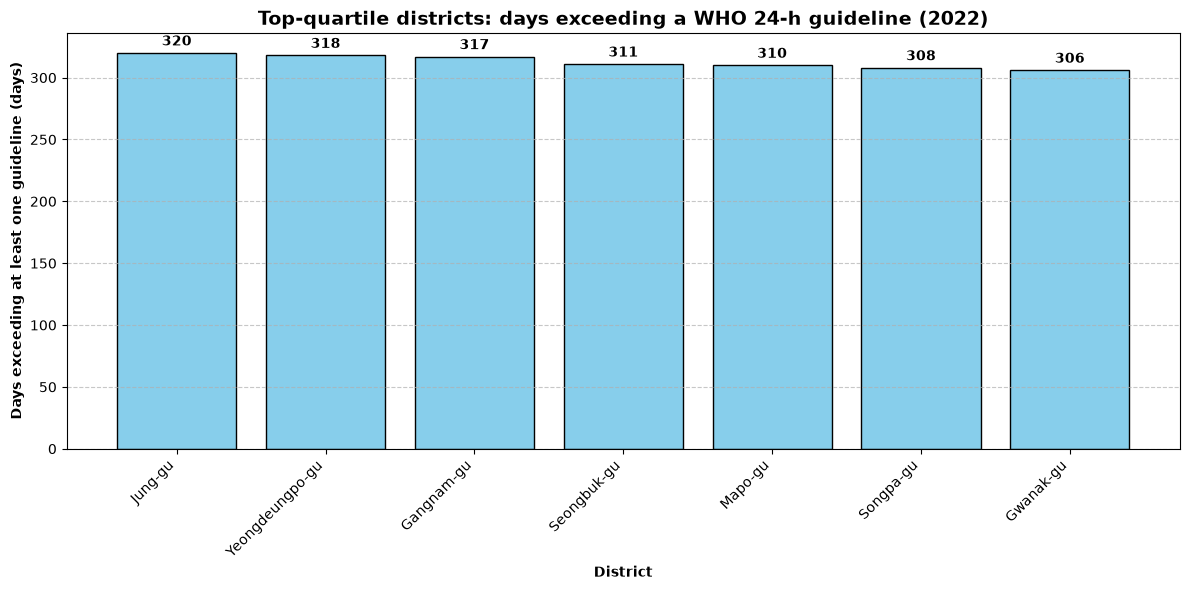

In [15]:

fig,ax=plt.subplots(figsize=(12,6))
bar=ax.bar(serious_pollution['district'],serious_pollution['total_days'],color='skyblue',edgecolor='black')
ax.bar_label(bar,padding=3,fontsize=10,fontweight='bold')
ax.set_title('Top-quartile districts: days exceeding a WHO 24-h guideline (2022)',fontsize=14,fontweight='bold')
ax.set_xlabel('District',fontsize=10,fontweight='bold')
ax.set_ylabel('Days exceeding at least one guideline (days)',fontsize=10,fontweight='bold')
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

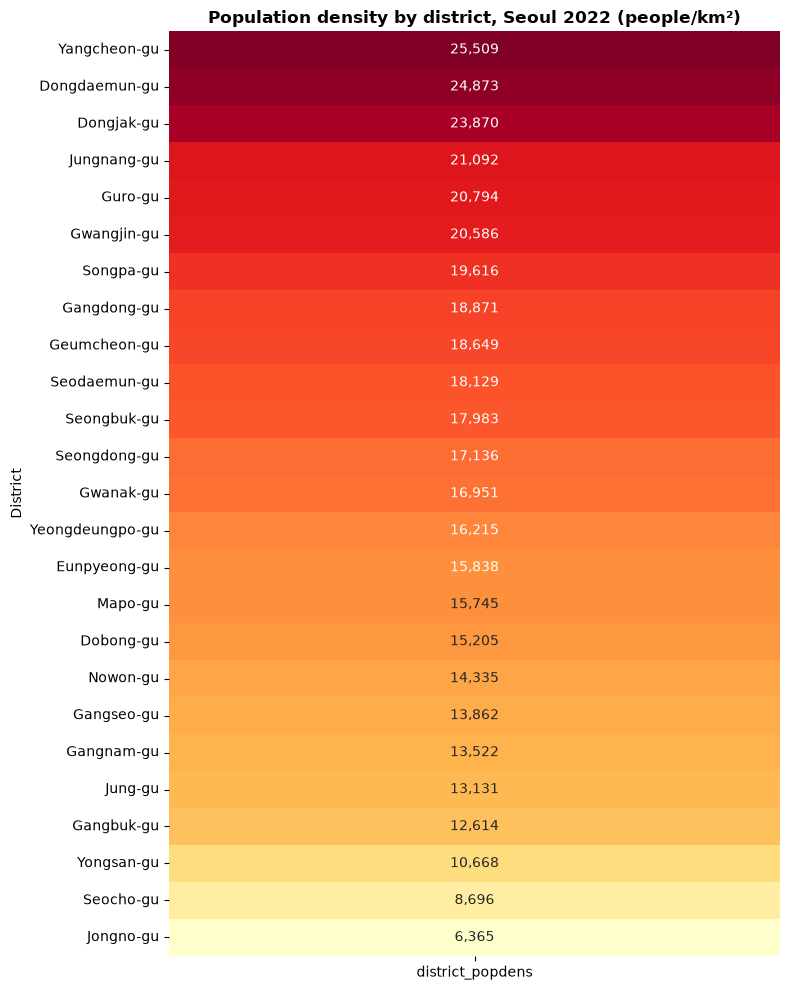

In [16]:
daily_sorted=district_summary.sort_values(by='district_popdens',ascending=False).set_index('district')
plt.figure(figsize=(8,10))
sns.heatmap(daily_sorted[['district_popdens']],annot=True,fmt=',.0f',cmap='YlOrRd',cbar=False)
plt.title('Population density by district, Seoul 2022 (people/km²)',fontsize=12,fontweight='bold')
plt.ylabel('District')
plt.tight_layout()
plt.show()

In [17]:
from adjustText import adjust_text

The goal of this project is to visualize the total pollution-exceeding days across the 25 districts  of Seoul in relation to population data,identifying the districts facing severe health risks to strategically determine optimal locations for new air quality monitoring station

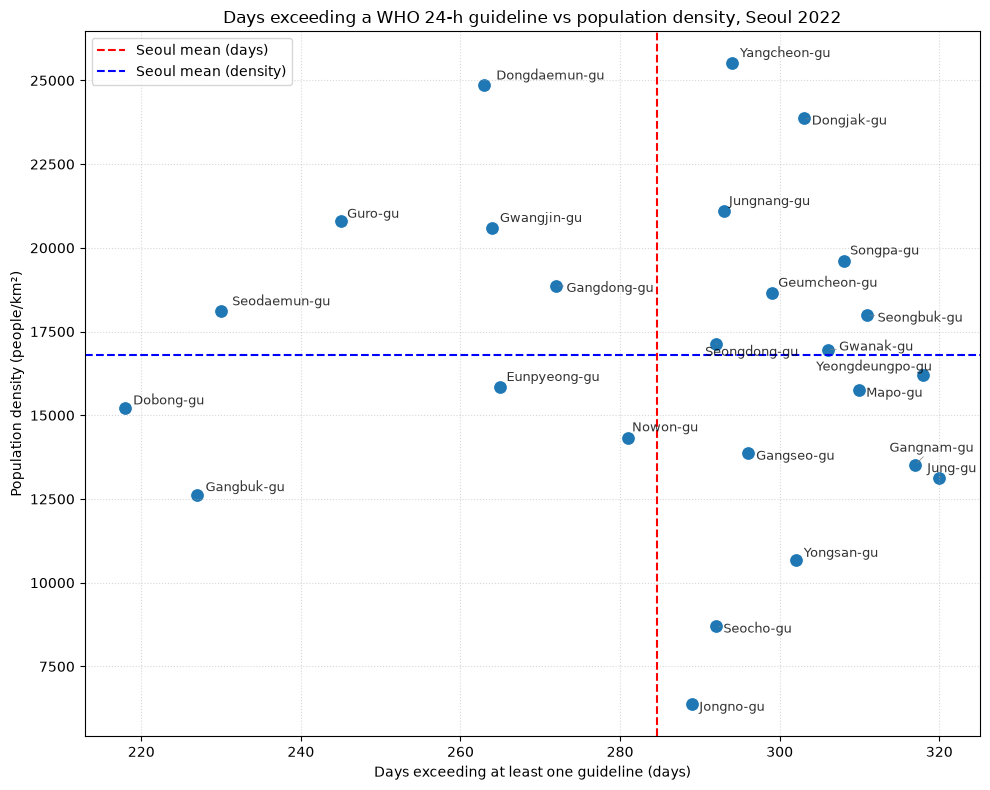

In [18]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=district_summary.reset_index(),x='total_days',y='district_popdens',s=100,legend=False)
mean_day=district_summary['total_days'].mean()
mean_pop=district_summary['district_popdens'].mean()
plt.axvline(mean_day,color='red',linestyle='--', label='Seoul mean (days)')
plt.axhline(mean_pop,color='blue',linestyle='--', label='Seoul mean (density)')     
texts=[]
for i in range(len(district_summary)):
      t=plt.text(district_summary['total_days'].iloc[i],
            district_summary['district_popdens'].iloc[i],
            district_summary['district'].iloc[i],
            fontsize=9,
            alpha=0.8)
      texts.append(t)
adjust_text(texts,arrowprops=dict(arrowstyle='-',color='gray',lw=0.5))
plt.title('Days exceeding a WHO 24-h guideline vs population density, Seoul 2022')
plt.xlabel('Days exceeding at least one guideline (days)')
plt.ylabel('Population density (people/km²)')
plt.legend()
plt.grid(True,linestyle=':',alpha=0.5)
plt.tight_layout()
plt.show()

## Statistical analysis

In [19]:
# District-level descriptive statistics (after imputation; all concentrations in ug/m3)
desc=(df.groupby('district').agg(PM25_mean=('PM2.5','mean'),PM25_median=('PM2.5','median'),PM25_p90=('PM2.5',lambda x:x.quantile(0.9)),
                                 PM10_mean=('PM10','mean'),PM10_median=('PM10','median'),PM10_p90=('PM10',lambda x:x.quantile(0.9)),
                                 NO2_mean=('NO2_ugm3','mean'),NO2_median=('NO2_ugm3','median'),NO2_p90=('NO2_ugm3',lambda x:x.quantile(0.9)))
      .reset_index()
      .merge(rule_df[['district','valid_days','total_rate','PM25_rate','PM10_rate','NO2_rate']],on='district',validate='one_to_one'))
print('Per district (rates = % of valid days above the WHO 24-h guideline):')
display(desc.round(1).sort_values('total_rate',ascending=False))
print('Seoul-wide hourly distribution:')
display(df[['PM2.5','PM10','NO2_ugm3']].describe(percentiles=[.5,.9]).round(1))

Per district (rates = % of valid days above the WHO 24-h guideline):


,district,PM25_mean,PM25_median,PM25_p90,PM10_mean,PM10_median,PM10_p90,NO2_mean,NO2_median,NO2_p90,valid_days,total_rate,PM25_rate,PM10_rate,NO2_rate
13,Jung-gu,19.3,16.0,37.0,29.8,26.0,53.0,44.8,37.6,84.6,361,88.6,56.5,15.0,84.2
23,Yeongdeungpo-gu,18.5,15.0,36.0,32.2,28.0,55.0,43.4,35.7,82.7,365,87.1,54.0,16.2,82.5
6,Gangnam-gu,17.6,15.0,34.0,32.1,28.0,55.0,42.8,35.7,79.0,364,87.1,51.1,16.8,84.1
19,Seongbuk-gu,17.7,15.0,35.0,33.4,28.0,62.0,44.2,35.7,86.5,363,85.7,49.9,21.5,83.2
21,Songpa-gu,18.4,16.0,34.0,34.0,30.0,56.0,45.7,37.6,87.4,361,85.3,55.1,18.6,81.7
10,Gwanak-gu,18.3,15.0,35.0,34.0,30.0,57.0,44.4,35.7,88.4,360,85.0,53.6,19.4,80.0
15,Mapo-gu,17.8,15.0,35.0,30.0,26.0,52.0,43.2,35.7,82.7,365,84.9,49.9,14.0,82.5
2,Dongjak-gu,20.2,17.0,38.0,35.0,30.0,61.0,40.4,32.0,82.7,363,83.5,63.1,22.3,73.0
24,Yongsan-gu,18.9,16.0,35.0,33.0,29.0,56.0,39.5,33.8,75.2,363,83.2,59.0,18.2,75.5
8,Geumcheon-gu,18.6,15.0,36.0,31.3,27.0,56.0,41.9,35.7,77.1,360,83.1,53.1,16.7,79.7


Seoul-wide hourly distribution:


,PM2.5,PM10,NO2_ugm3
count,216545.0,216545.0,216545.0
mean,18.4,32.8,39.2
std,13.9,22.7,25.1
min,1.0,1.0,1.9
50%,15.0,28.0,32.0
90%,36.0,57.0,77.1
max,126.0,482.0,180.5


*The next table is exploratory: it is computed per district and month in the original units (NO2 and CO in ppm; `p90` = 90th percentile).*

In [20]:
stats_result=df.groupby(['district','month']).agg({'PM2.5':['mean','median','std',('p90',lambda x:x.quantile(0.9))],'PM10':['mean','median','std',('p90',lambda x:x.quantile(0.9))],
                                                   'NO2':['mean','median','std',('p90',lambda x:x.quantile(0.9))],'CO':['mean','median','std',('p90',lambda x:x.quantile(0.9))]})
stats_result.columns=['_'.join(col).strip() for col in stats_result.columns.values]
stats_result=stats_result.reset_index()
print(stats_result.head())

    district  month  PM2.5_mean  PM2.5_median  PM2.5_std  PM2.5_p90  \
0  Dobong-gu      1   28.097166          23.0  19.102816       49.0   
1  Dobong-gu      2   25.248882          18.0  18.534495       52.0   
2  Dobong-gu      3   21.953504          17.0  16.396082       45.0   
3  Dobong-gu      4   21.400581          21.0  12.909425       39.0   
4  Dobong-gu      5   15.880054          14.0   9.957557       27.0   

   PM10_mean  PM10_median   PM10_std  PM10_p90  NO2_mean  NO2_median  \
0  44.373819         39.0  21.933051      69.0  0.025240      0.0220   
1  38.272727         33.0  20.658239      66.0  0.019869      0.0140   
2  39.078167         33.0  30.178215      71.0  0.020363      0.0175   
3  41.330914         39.0  28.965260      65.2  0.016025      0.0130   
4  31.721698         30.0  15.518253      50.0  0.011472      0.0100   

    NO2_std  NO2_p90   CO_mean  CO_median    CO_std  CO_p90  
0  0.014667    0.047  0.692038        0.6  0.282551     1.1  
1  0.015271    0

**Note on the next two cells.** The hourly-record correlation matrix and its heatmap are exploratory. Population and population density are constants within each district, so correlations with them across 216,545 hourly rows are not valid evidence (the effective sample is 25 districts). The valid test of the density–PM2.5 relationship is the district-level analysis (n = 25) further below.

In [21]:
#Correlation between population density and PM2.5
corr_matrix=df[['population_density','population','CO','NO2','O3','PM2.5','PM10']].corr()
print(corr_matrix)
correlation=df['population_density'].corr(df['PM2.5'])
display(correlation)

                    population_density  population        CO       NO2  \
population_density            1.000000    0.293346 -0.010590  0.003569   
population                    0.293346    1.000000  0.013441  0.036016   
CO                           -0.010590    0.013441  1.000000  0.739925   
NO2                           0.003569    0.036016  0.739925  1.000000   
O3                           -0.018150   -0.030800 -0.359378 -0.515450   
PM2.5                         0.011498    0.002968  0.626794  0.495888   
PM10                          0.022761    0.037727  0.443375  0.368668   

                          O3     PM2.5      PM10  
population_density -0.018150  0.011498  0.022761  
population         -0.030800  0.002968  0.037727  
CO                 -0.359378  0.626794  0.443375  
NO2                -0.515450  0.495888  0.368668  
O3                  1.000000 -0.002412  0.050138  
PM2.5              -0.002412  1.000000  0.768416  
PM10                0.050138  0.768416  1.000000  

np.float64(0.011497504800205872)

In [22]:
#Group by districts
district_analysis = df.groupby('district').agg(
    avg_pm25=('PM2.5', 'mean'),
    population_density=('population_density', 'first')
).reset_index()

In [23]:
#Calculate Pearson correlation
from scipy.stats import pearsonr

r, p = pearsonr(
    district_analysis['population_density'],
    district_analysis['avg_pm25']
)

print("Pearson r:", r)
print("P-value:", p)
print("Sample size:", len(district_analysis))

Pearson r: 0.14507023976559538
P-value: 0.48900651722859123
Sample size: 25


In [24]:
print(df[['NO2', 'CO']].describe())

print(df[['NO2_ugm3', 'CO_ugm3']].describe())

                 NO2             CO
count  216545.000000  216545.000000
mean        0.020866       0.437129
std         0.013369       0.185465
min         0.001000       0.100000
25%         0.011000       0.300000
50%         0.017000       0.400000
75%         0.028000       0.500000
max         0.096000       2.000000
            NO2_ugm3        CO_ugm3
count  216545.000000  216545.000000
mean       39.228558     500.512973
std        25.132940     212.357087
min         1.880000     114.500000
25%        20.680000     343.500000
50%        31.960000     458.000000
75%        52.640000     572.500000
max       180.480000    2290.000000


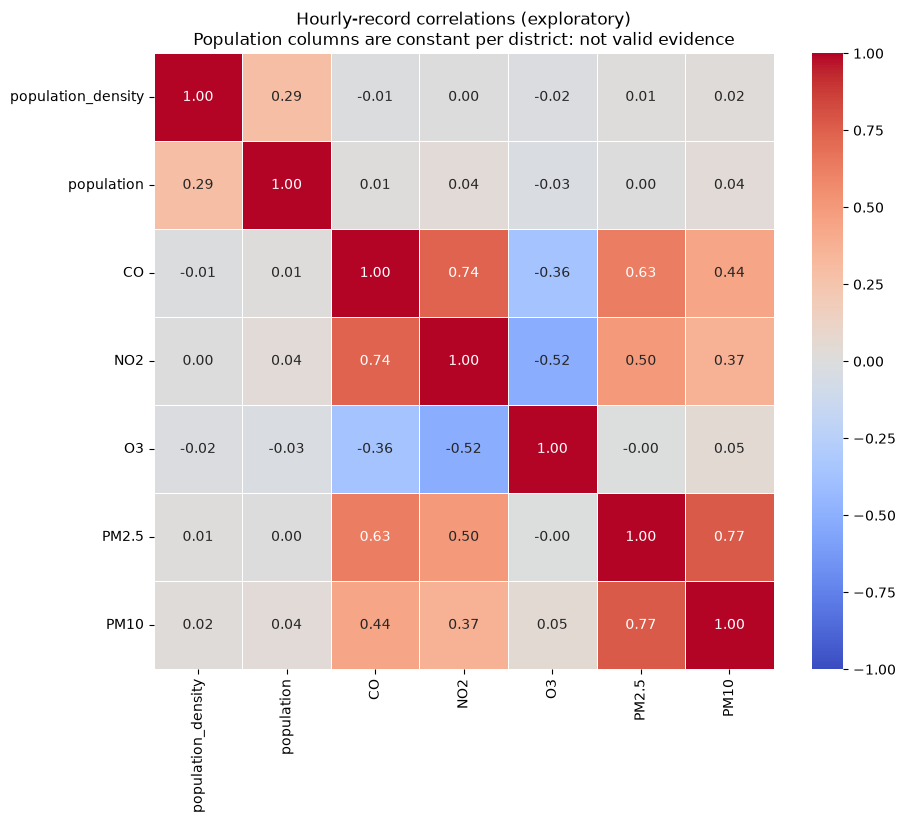

In [25]:
plt.figure(figsize=(10,8))
sns.heatmap(data=corr_matrix,
           annot=True,
           cmap='coolwarm',
           fmt='.2f',
           linewidths=0.5,
           cbar=True,
           vmin=-1,vmax=1)
plt.title("Hourly-record correlations (exploratory)\nPopulation columns are constant per district: not valid evidence")
plt.show()

District-level relationship (n=25)

In [26]:
dist_stats=(df.groupby('district')
            .agg(avg_pm25=('PM2.5','mean'),density=('population_density','first'),
                 population=('population','first'),area_km2=('area_km2','first'))
            .reset_index()
            .merge(rule_df[['district','PM25_rate']],on='district',validate='one_to_one'))

rows=[]
for x,y in [('density','avg_pm25'),('density','PM25_rate'),('population','avg_pm25'),('area_km2','avg_pm25')]:
    r,p=stats.pearsonr(dist_stats[x],dist_stats[y])
    rho,ps=stats.spearmanr(dist_stats[x],dist_stats[y])
    lr=stats.linregress(dist_stats[x],dist_stats[y])
    rows.append({'x':x,'y':y,'n':len(dist_stats),'pearson_r':r,'p_pearson':p,
                 'spearman_rho':rho,'p_spearman':ps,'slope':lr.slope,'R2':lr.rvalue**2})
corr_table=pd.DataFrame(rows)
display(corr_table.round(6))

high=dist_stats['density']>=dist_stats['density'].quantile(0.75)
u,p_u=stats.mannwhitneyu(dist_stats.loc[high,'avg_pm25'],dist_stats.loc[~high,'avg_pm25'],alternative='two-sided')
print(f"District-average PM2.5 - top-quartile-density districts (n={high.sum()}) median={dist_stats.loc[high,'avg_pm25'].median():.2f} "
      f"vs others (n={(~high).sum()}) median={dist_stats.loc[~high,'avg_pm25'].median():.2f} | Mann-Whitney U={u:.1f}, p={p_u:.3f}")

,x,y,n,pearson_r,p_pearson,spearman_rho,p_spearman,slope,R2
0,density,avg_pm25,25,0.145070,0.489007,0.044615,0.832293,0.000035,0.021045
1,density,PM25_rate,25,0.130844,0.533012,0.033846,0.872399,0.000146,0.017120
2,population,avg_pm25,25,0.036039,0.864203,0.023846,0.909918,0.000000,0.001299
3,area_km2,avg_pm25,25,-0.083801,0.690441,-0.110000,0.600672,-0.010243,0.007023


District-average PM2.5 - top-quartile-density districts (n=7) median=18.43 vs others (n=18) median=18.37 | Mann-Whitney U=75.0, p=0.495


### Relationship between Population Density and PM2.5

A district-level Pearson correlation analysis was conducted to examine the relationship between population density and average PM2.5 concentration across Seoul's 25 districts.

The analysis showed a weak positive correlation (r = 0.145, p = 0.489, n = 25). The relationship was not statistically significant at the conventional 0.05 significance level.

The corresponding simple linear model had an R² of approximately 0.021, indicating that population density alone explained only around 2.1% of the variation in district-level average PM2.5.

These results do not establish a causal relationship between population density and air pollution. Other factors, including traffic emissions, weather conditions, land use and industrial activities, may also influence PM2.5 concentrations.

The analysis is limited to 25 district-level observations from Seoul in 2022 and should not be generalized to other cities or years without further investigation.

For the PM2.5 exceedance rate, density gave r = 0.131 (p = 0.533, Spearman ρ = 0.034). The Mann–Whitney comparison of the top-quartile-density districts with the rest also showed no difference (p = 0.495). Density therefore does not predict pollution hazard in this data, which is why the screening treats hazard and exposure as separate criteria rather than one driving the other. Four relationships were tested without adjustment for multiple comparisons; none was significant.

**Figures for the report.** Figures 1–4 below (monthly trend, district bar chart, density scatter, screening heatmap) are the report figures. The earlier charts (hourly histograms, missing-hours heatmap, top-quartile bar chart, density heatmap, exploratory scatter and correlation heatmap) are exploratory.

# Step 3.2 - Exploratory Data Visualization

## Visualization Lead

### Chart 1: Monthly PM2.5 Trend in Seoul (2022)
#### How does the average PM2.5 concentration in Seoul change from January to December 2022?

In [27]:
#Data Validation / Data Inspection
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df[['datetime', 'district', 'month', 'PM2.5']].head())

print("\nMissing PM2.5:")
print(df['PM2.5'].isna().sum())


Dataset shape: (216545, 25)

Columns:
    datetime      district  month  PM2.5
0 2022-01-01     Jongno-gu      1   12.0
1 2022-01-01       Jung-gu      1   10.0
2 2022-01-01    Yongsan-gu      1   13.0
3 2022-01-01  Eunpyeong-gu      1   10.0
4 2022-01-01  Seodaemun-gu      1   13.0

Missing PM2.5:
0


In [28]:
## Calculate average PM2.5 for each district and month
district_monthly = (df.groupby(['district','month'])['PM2.5'].mean().reset_index(name='avg_pm25'))
display(district_monthly.head())


,district,month,avg_pm25
0,Dobong-gu,1,28.097166
1,Dobong-gu,2,25.248882
2,Dobong-gu,3,21.953504
3,Dobong-gu,4,21.400581
4,Dobong-gu,5,15.880054


In [29]:
#check after calculate average PM2.5 for each district and month
print("Shape:", district_monthly.shape)
print("Number of districts:", district_monthly['district'].nunique())
print("Number of months:", district_monthly['month'].nunique())
print("Missing averages:", district_monthly['avg_pm25'].isna().sum())

Shape: (300, 3)
Number of districts: 25
Number of months: 12
Missing averages: 0


In [30]:
##Calculate average PM2.5 for each month 
monthly_pm25 = (district_monthly.groupby(['month'])['avg_pm25'].mean().reset_index())
display(monthly_pm25.head())

,month,avg_pm25
0,1,28.697891
1,2,25.487815
2,3,21.156026
3,4,21.742372
4,5,16.845483


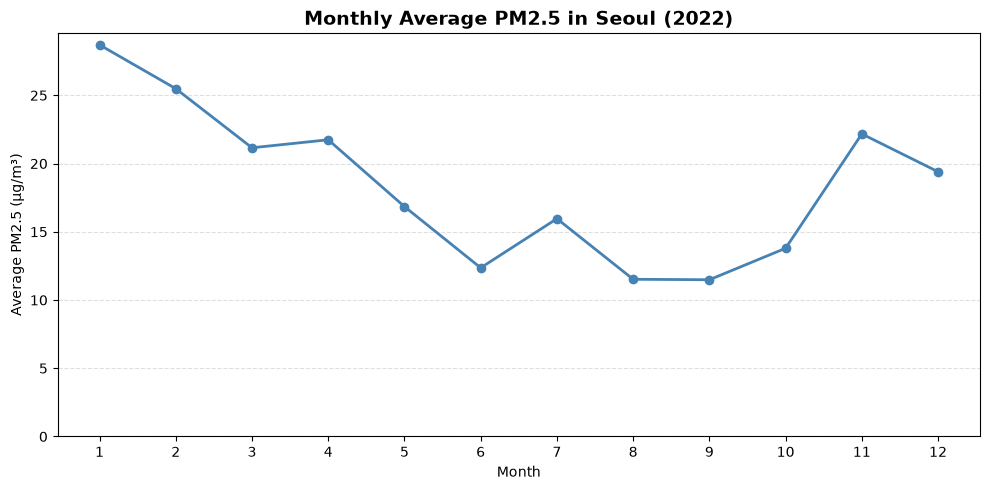

In [31]:

# Chart 1 - Line chart: Monthly PM2.5 Trend in Seoul

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_pm25['month'],
    monthly_pm25['avg_pm25'],
    marker='o',
    color='steelblue',
    linewidth=2,
    markersize=6
)

ax.set_title(
    'Monthly Average PM2.5 in Seoul (2022)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Month')
ax.set_ylabel('Average PM2.5 (µg/m³)')

ax.set_xticks(range(1, 13))
ax.set_ylim(bottom=0)

ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


In [32]:
print("Shape:", monthly_pm25.shape)
print("Unique months:", monthly_pm25['month'].nunique())
print("Missing values:")
print(monthly_pm25.isna().sum())
display(monthly_pm25.sort_values('month'))


Shape: (12, 2)
Unique months: 12
Missing values:
month       0
avg_pm25    0
dtype: int64


,month,avg_pm25
0,1,28.697891
1,2,25.487815
2,3,21.156026
3,4,21.742372
4,5,16.845483
5,6,12.358544
6,7,15.961750
7,8,11.520690
8,9,11.486134
9,10,13.793450


In [33]:
district_count = (district_monthly.groupby('month')['district'].nunique())
display(district_count)


month
1     25
2     25
3     25
4     25
5     25
6     25
7     25
8     25
9     25
10    25
11    25
12    25
Name: district, dtype: int64

In [34]:
#Which month recorded the highest average PM2.5 concentration?
highest_month = monthly_pm25.loc[monthly_pm25['avg_pm25'].idxmax()]
print(highest_month)


month        1.000000
avg_pm25    28.697891
Name: 0, dtype: float64


In [35]:
#Which month recorded the lowest average PM2.5 concentration?
lowest_month = monthly_pm25.loc[monthly_pm25['avg_pm25'].idxmin()]
print(lowest_month)

month        9.000000
avg_pm25    11.486134
Name: 8, dtype: float64


**Figure 1. Monthly average PM2.5 in Seoul, 2022 (µg/m³; mean of the 25 district-monthly averages, after imputation).**

**Key finding:** January recorded the highest monthly average (28.70 µg/m³), about 2.5 times the lowest, September (11.49 µg/m³). Values are highest in winter and early spring and lowest from June to October.

**Interpretation limitation:** These observations describe patterns in the 2022 dataset and do not establish the causes of seasonal variation.

# Chart 2: Bar Chart: Compare average pollution levels across 25 districts
### Which districts recorded the highest and lowest average PM2.5 in 2022?

In [36]:
# Average PM2.5 concentration by district
district_pm25 = (df.groupby('district')['PM2.5'].mean().reset_index(name='avg_pm25'))
display(district_pm25.head())


,district,avg_pm25
0,Dobong-gu,16.930747
1,Dongdaemun-gu,19.199229
2,Dongjak-gu,20.227142
3,Eunpyeong-gu,19.083727
4,Gangbuk-gu,18.321133


In [37]:
# Sort the descending values (from the highest values to the lowest values)
district_pm25 = district_pm25.sort_values('avg_pm25', ascending=False)
display(district_pm25.head(10))


,district,avg_pm25
16,Nowon-gu,20.446866
22,Yangcheon-gu,20.227744
2,Dongjak-gu,20.227142
13,Jung-gu,19.305738
12,Jongno-gu,19.276894
1,Dongdaemun-gu,19.199229
3,Eunpyeong-gu,19.083727
24,Yongsan-gu,18.872482
5,Gangdong-gu,18.838400
8,Geumcheon-gu,18.564338


In [38]:
#Validate PM2.5
print("Shape:", district_pm25.shape)
print("Number of districts:", district_pm25['district'].nunique())

print("Missing values:", district_pm25['avg_pm25'].isna().sum())


Shape: (25, 2)
Number of districts: 25
Missing values: 0


In [39]:
print("Sorted descending:", district_pm25['avg_pm25'].is_monotonic_decreasing)

Sorted descending: True


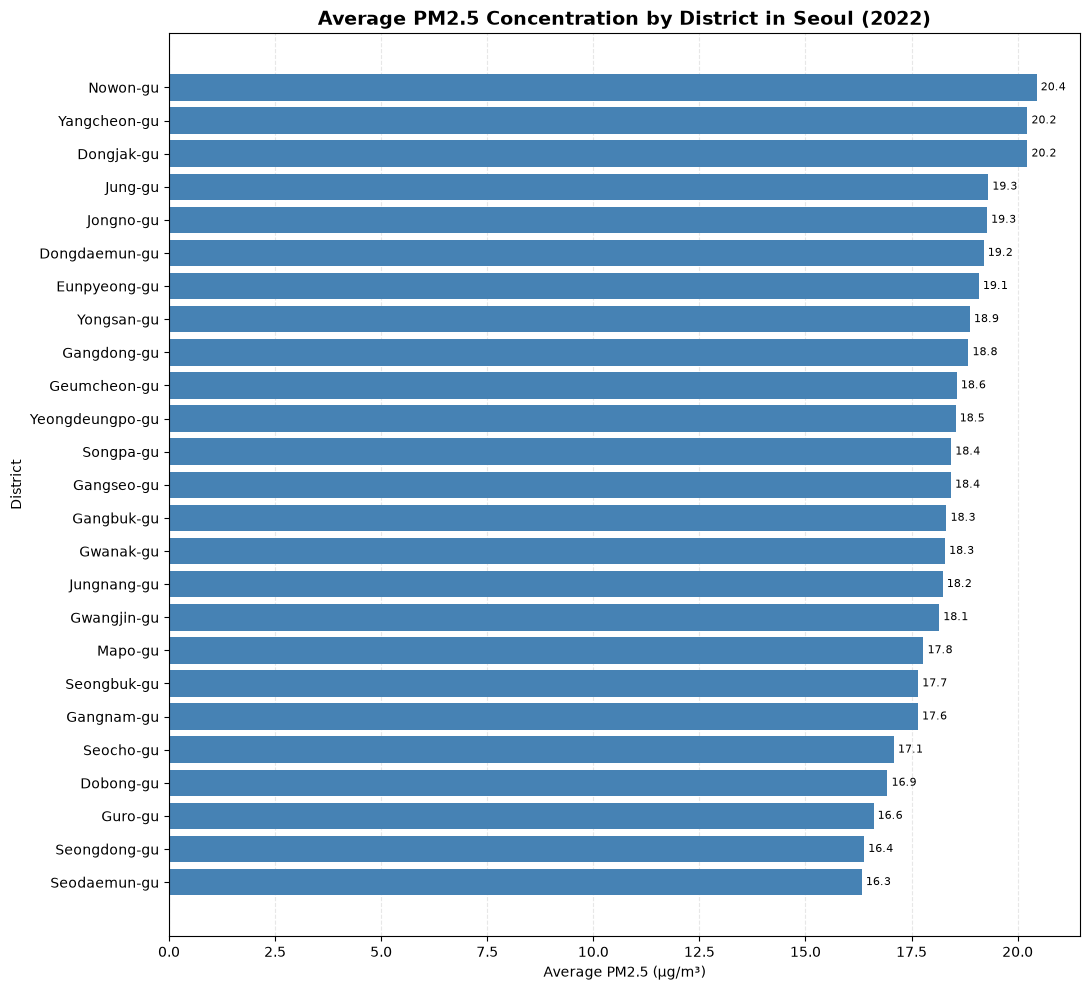

In [40]:
# Chart 2: Average PM2.5 by District in Seoul
fig, ax = plt.subplots(figsize=(11, 10))

bars = ax.barh(
    district_pm25['district'],
    district_pm25['avg_pm25'],
    color='steelblue'
)

# Highest concentration at the top
ax.invert_yaxis()

# Title and axis labels
ax.set_title('Average PM2.5 Concentration by District in Seoul (2022)', fontsize=14, fontweight='bold')

ax.set_xlabel('Average PM2.5 (µg/m³)')
ax.set_ylabel('District')

# Start the value axis at zero
ax.set_xlim(left=0)

# Display values
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

# Grid
ax.grid( axis='x', linestyle='--', alpha=0.3 )
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [41]:
#Validate Bar Chart
print("Number of bars:", len(bars))

highest_district = district_pm25.iloc[0]
lowest_district = district_pm25.iloc[-1]

print("Highest PM2.5:")
print(highest_district)

print("\nLowest PM2.5:")
print(lowest_district)


Number of bars: 25
Highest PM2.5:
district     Nowon-gu
avg_pm25    20.446866
Name: 16, dtype: object

Lowest PM2.5:
district    Seodaemun-gu
avg_pm25       16.326301
Name: 18, dtype: object


**Figure 2. Average PM2.5 concentration across Seoul's 25 districts in 2022 (µg/m³; after imputation).**

**Key finding:** Nowon-gu recorded the highest average (20.4 µg/m³) and Seodaemun-gu the lowest (16.3 µg/m³). The whole spread is only about 4 µg/m³, so the ranking should not be over-interpreted. Nowon-gu passes the screening rule but is not among the five shortlisted districts (Figure 4), because the shortlist ranks districts on several hazard and exposure measures, not on mean PM2.5 alone.

**Limitation:** Each district's value comes from one monitoring station and may not represent the whole district. Dongdaemun-gu is missing 551 hours in August, which probably biases its average upward.

# Chart 3: Scatter Plot + Trendline: Relationship between Population Density (X) and Pollution (Y).
### Is there a relationship between population density and average PM2.5 concentration across Seoul's 25 districts?

In [42]:
#check whether the population density is fixed
df.loc[
    df['district'] == 'Gangnam-gu',
    ['datetime', 'district', 'PM2.5', 'population_density']
].head(10)


,datetime,district,PM2.5,population_density
22,2022-01-01 00:00:00,Gangnam-gu,9.0,13522
47,2022-01-01 01:00:00,Gangnam-gu,8.0,13522
72,2022-01-01 02:00:00,Gangnam-gu,7.0,13522
97,2022-01-01 03:00:00,Gangnam-gu,7.0,13522
122,2022-01-01 04:00:00,Gangnam-gu,11.0,13522
147,2022-01-01 05:00:00,Gangnam-gu,9.0,13522
172,2022-01-01 06:00:00,Gangnam-gu,9.0,13522
197,2022-01-01 07:00:00,Gangnam-gu,11.0,13522
222,2022-01-01 08:00:00,Gangnam-gu,12.0,13522
247,2022-01-01 09:00:00,Gangnam-gu,10.0,13522


In [43]:
# Population density for each district
population_density_by_district = (
    df.groupby('district')['population_density']
    .first()
    .reset_index()
)

display(population_density_by_district.head())


,district,population_density
0,Dobong-gu,15205
1,Dongdaemun-gu,24873
2,Dongjak-gu,23870
3,Eunpyeong-gu,15838
4,Gangbuk-gu,12614


In [44]:
# Merge PM2.5 and population density by district
scatter_df = pd.merge(
    district_pm25,
    population_density_by_district,
    on='district',
    how='inner',
    validate='one_to_one'
)

display(scatter_df.head())


,district,avg_pm25,population_density
0,Nowon-gu,20.446866,14335
1,Yangcheon-gu,20.227744,25509
2,Dongjak-gu,20.227142,23870
3,Jung-gu,19.305738,13131
4,Jongno-gu,19.276894,6365


In [45]:
#Validate scatter_df - Check whether the merge operation results in the loss or duplication of rows.
print("Shape:", scatter_df.shape)
print(
    "Number of districts:",
    scatter_df['district'].nunique()
)

print("\nMissing values:")
print(scatter_df.isna().sum())


Shape: (25, 3)
Number of districts: 25

Missing values:
district              0
avg_pm25              0
population_density    0
dtype: int64


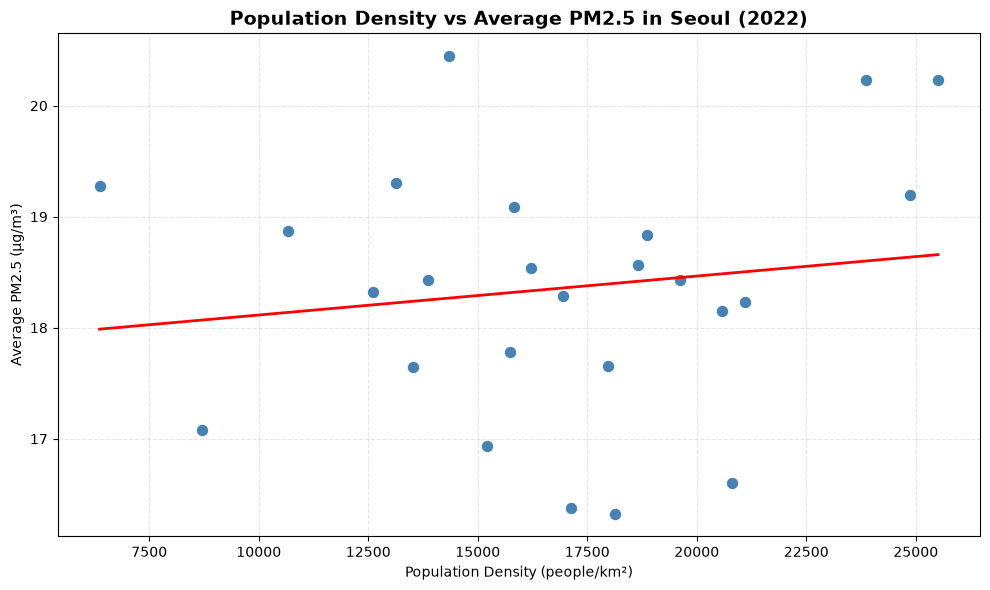

In [46]:
# Chart 3: Population Density vs Average PM2.5

fig, ax = plt.subplots(figsize=(10, 6))

# Scatter Plot
sns.scatterplot(
    data=scatter_df,
    x='population_density',
    y='avg_pm25',
    s=80,
    color='steelblue',
    ax=ax
)

# Trendline
sns.regplot(
    data=scatter_df,
    x='population_density',
    y='avg_pm25',
    scatter=False,
    ci=None,
    color='red',
    line_kws={'linewidth': 2},
    ax=ax
)

ax.set_title(
    'Population Density vs Average PM2.5 in Seoul (2022)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Population Density (people/km²)')
ax.set_ylabel('Average PM2.5 (µg/m³)')

ax.grid(linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Figure 3. Relationship Between Population Density and Average PM2.5 Across Seoul's 25 Districts.**

**Key finding:** The scatter plot indicates a weak positive relationship between population density and average PM2.5. The district-level Pearson correlation was 0.145 (p = 0.489), providing insufficient statistical evidence of a linear association at the 0.05 significance level.

**Limitation:** The observed relationship does not imply causation. Other environmental and socioeconomic factors may contribute to differences in air pollution across districts.

*n = 25 districts. The red line is the least-squares fit, shown for description only: the slope is not statistically significant (r = 0.145, p = 0.489; Spearman ρ = 0.045), so it should not be read as evidence of a relationship.*

# Chart 4: Heatmap: District Screening Heatmap
### Which districts meet the screening criteria?

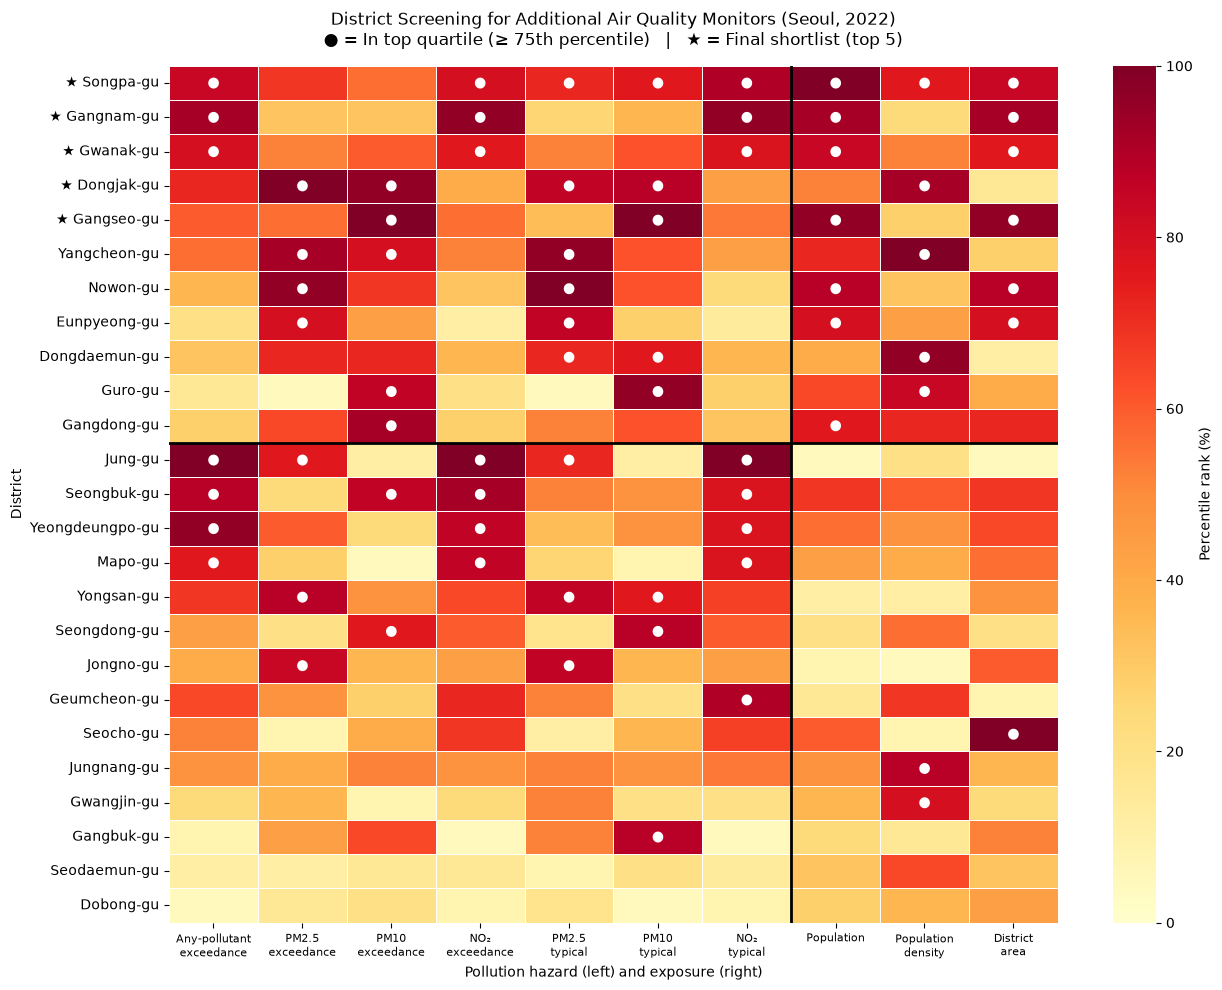

In [47]:
# 1. Choose the criteria and sort districts that pass the rule to the top
cols = hazard_cols + exposure_cols

table = rule_res.sort_values(
    ['shortlisted', 'score', 'total_rate'],
    ascending=False
).set_index('district')

# 2. Colour by percentile rank; dots mark measures in the top quartile
colors = table[cols].rank(pct=True) * 100

top_cols = [f'{col}_top' for col in cols]
dots = table[top_cols].replace({True: '●', False: ''})

# 3. Column names; add a star next to shortlisted districts
column_names = {
    'total_rate': 'Any-pollutant\nexceedance',
    'PM25_rate': 'PM2.5\nexceedance',
    'PM10_rate': 'PM10\nexceedance',
    'NO2_rate': 'NO₂\nexceedance',
    'PM25_typical': 'PM2.5\ntypical',
    'PM10_typical': 'PM10\ntypical',
    'NO2_typical': 'NO₂\ntypical',
    'district_population': 'Population',
    'district_popdens': 'Population\ndensity',
    'dis_area': 'District\narea',
}

final_districts = set(final_shortlist['district'])
district_names = [
    f'★ {district}' if district in final_districts else district
    for district in table.index
]

# 4. Draw the heatmap
fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    colors,
    annot=dots.to_numpy(),
    fmt='',
    cmap='YlOrRd',
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor='white',
    xticklabels=[column_names[col] for col in cols],
    yticklabels=district_names,
    cbar_kws={'label': 'Percentile rank (%)'},
    ax=ax
)

# Vertical line separates hazard and exposure criteria
ax.axvline(len(hazard_cols), color='black', linewidth=2)

# Horizontal line separates districts that pass the rule from those that do not
n_pass = int(table['shortlisted'].sum())
if 0 < n_pass < len(table):
    ax.axhline(n_pass, color='black', linewidth=2)

ax.set_title(
    'District Screening for Additional Air Quality Monitors (Seoul, 2022)\n'
    '● = In top quartile (≥ 75th percentile)   |   ★ = Final shortlist (top 5)',
    pad=15
)
ax.set_xlabel('Pollution hazard (left) and exposure (right)')
ax.set_ylabel('District')
ax.tick_params(axis='x', labelrotation=0, labelsize=8)
ax.tick_params(axis='y', labelrotation=0)

plt.tight_layout()
plt.show()

**Figure 4. District screening heatmap (percentile rank of each district on 7 hazard and 3 exposure measures, Seoul 2022).**

**Interpretation:** The heatmap displays percentile ranks for each district relative to the other 24 districts. A higher percentile indicates a relatively higher position for that indicator within the comparison group. These percentile ranks are not raw pollution concentrations or percentages of unhealthy days.

**Limitation:** The screening results are intended to identify districts for further investigation, not to establish that a particular district requires additional monitoring equipment without further field assessment.

**Reading the chart:** the thick horizontal line separates the 11 districts that pass the rule (above) from the other 14. Only the top five (★) are shortlisted. Yangcheon-gu, Nowon-gu and Eunpyeong-gu pass the rule but are not starred: they score 4, and Gangseo-gu (also 4) takes the fifth place on the tie-break. "Typical" means the median of daily medians. Columns headed "exceedance" are the share of valid days above the WHO 24-hour guideline.

## Recommendation

We recommend that Seoul's Air Quality Integrated Analysis Center prioritise Songpa-gu, Gangnam-gu, Gwanak-gu, Dongjak-gu, and Gangseo-gu for further assessment of air-quality monitoring coverage.

| Priority | District | Main pollution evidence | Demographic exposure criteria met |
|---|---|---|---|
| 1 | Songpa-gu | High NO2 exceedance rate and high typical levels across the three pollutants | Population, population density, and district area |
| 2 | Gangnam-gu | High NO2 exceedance rate and high typical NO2 level | Population and district area |
| 3 | Gwanak-gu | High NO2 exceedance rate and high typical NO2 level | Population and district area |
| 4 | Dongjak-gu | High PM2.5 and PM10 exceedance rates | Population density |
| 5 | Gangseo-gu | High PM10 exceedance rate and high typical PM10 level | Population and district area |

This recommendation uses 2022 data and supports a decision about which districts to assess first. To choose specific monitoring sites, the city would also need information on existing station coverage, where people live within each district, and the location of local emission sources.

**Assumptions.** (1) The WHO 2021 24-hour guideline values are an appropriate yardstick for "hazard"; Korean national standards are less strict and would give fewer exceedance days. (2) Resident population, density and area are acceptable proxies for exposure (daytime populations, e.g. in Jung-gu, are not captured). (3) Imputed values and the 18-hours-per-day rule do not materially change district rankings. (4) One year of data is representative.

**What would change the recommendation.** Adding existing-station coverage within districts, daytime population or traffic and emission-source data; using the national standards instead of the WHO values; or a different top-quartile cut-off, which would alter the lower-ranked places (Gangseo-gu in fifth place is the least certain).